# Benchmark - analysis
All the games played, old and new, in one table (one row per game), and the graphs of the comparison between models and modes.
Run it locally: copy the results folder from Google Drive (`MyDrive/LLMs-Play-Textual-Games/Benchmark/results`) into `Code/Benchmark/results_new`.

In [1]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bootstrap

sys.path.insert(0, os.getcwd())
from records import LEGACY_RESULTS, load_table

folders = [LEGACY_RESULTS, "results_new"] # the old experiments, the games played by run.py
table = load_table(*[folder for folder in folders if os.path.isdir(folder)])
print(f"{len(table)} games")
table.groupby(["model", "prompt", "game", "mode"]).size().unstack("mode").fillna(0).astype(int)

8140 games


mode                                          0   e1  er10  er4  l1  lr4  r10  \
model             prompt  game                                                  
Qwen/Qwen3-1.7B   CoT     cooking            50   50     0   50   0   50    0   
Qwen/Qwen3-4B     CoT     coin_collector      0  140     0    0   0    0  280   
                          connect_four        0    4     0    0   0    0    0   
                          cooking             0   90     1  100   0   90  180   
                          treasure_hunter     0  270     0    0   0    0  540   
                  default coin_collector    500  140     0    0   0    0  280   
                          cooking           450   90     0    0   0    0  180   
                          treasure_hunter  1350  270     0    0   0    0  540   
                  free    chess               0    4     0    4   0    4    0   
                          connect_four        0   10     0   10  10   10    0   
                  neutral chess               0    2     0    2   0    2    0   
                          connect_four        0    4     0    0   0    0    0   
                  plain   chess               0    2     0    2   0    2    0   
                          connect_four        0   10     0   10  10   10    0   
Qwen/Qwen3-8B-FP8 CoT     cooking            50   50     0   50   0   50    0   

mode                                        r4  
model             prompt  game                  
Qwen/Qwen3-1.7B   CoT     cooking           50  
Qwen/Qwen3-4B     CoT     coin_collector   280  
                          connect_four       4  
                          cooking          180  
                          treasure_hunter  540  
                  default coin_collector   280  
                          cooking          180  
                          treasure_hunter  540  
                  free    chess              5  
                          connect_four      10  
                  neutral chess              2  
                          connect_four       4  
                  plain   chess              2  
                          connect_four      10  
Qwen/Qwen3-8B-FP8 CoT     cooking           50

# Selection
The games compared: every model and mode on the same games (same levels and seeds), so that the averages are comparable.
`models` is the order of the graphs (by size); the models without games are left out.
Tokens: the old Qwen3-4B r4-think games have logs only for seeds 11-20, so the tokens are averaged on `token_seeds`.

In [2]:
prompt = "CoT"
game = "cooking"
levels = [1, 3, 5, 7, 9]
seeds = range(1, 11)
token_seeds = range(1, 21)
modes = ["0", "e1", "r4", "er4", "lr4"]
models = ["Qwen/Qwen3-0.6B", "Qwen/Qwen3-1.7B", "Qwen/Qwen3-4B", "Qwen/Qwen3-8B-FP8", "Qwen/Qwen3-14B-AWQ",
          "HuggingFaceTB/SmolLM3-3B", "deepseek-ai/DeepSeek-R1-Distill-Llama-8B"]

selected = table[(table.prompt == prompt) & (table.game == game) & table.level.isin(levels)]
scores = selected[selected.seed.isin(seeds)]
tokens = selected[selected.seed.isin(token_seeds) & selected.tokens_generated.notna()]
models = [model for model in models if model in set(scores.model)]
modes = [mode for mode in modes if mode in set(scores["mode"])]
short = {model: model.split("/")[-1] for model in models}

def mean_ci(values):
    """Mean and 90% bootstrap confidence interval (the mean itself when there are less than 2 values)."""
    values = np.asarray(values, dtype=float)
    if len(values) < 2:
        return values.mean() if len(values) else np.nan, np.nan, np.nan
    ci = bootstrap((values,), np.mean, method="basic", n_resamples=1000, confidence_level=0.9).confidence_interval
    return values.mean(), ci.low, ci.high

summary = []
for model in models:
    for mode in modes:
        s = scores[(scores.model == model) & (scores["mode"] == mode)]
        t = tokens[(tokens.model == model) & (tokens["mode"] == mode)]
        if len(s) == 0:
            continue
        summary.append(dict(model=short[model], mode=mode, games=len(s), score=s.norm_score.mean(),
                            ktokens_per_game=t.tokens_generated.mean() / 1000, token_games=len(t),
                            loops=s.loop_stopped.fillna(False).sum()))
import pandas as pd
pd.DataFrame(summary).set_index(["model", "mode"]).round(2)

games  score  ktokens_per_game  token_games  loops
model        mode                                                    
Qwen3-1.7B   0        50   0.02              1.62           50     24
             e1       50   0.21             42.93           50      8
             r4       50   0.05              5.07           50     13
             er4      50   0.04              2.43           50      7
             lr4      50   0.06              2.97           50      3
Qwen3-4B     e1       50   0.47             61.65           50      0
             r4       50   0.24              7.03           47      0
             er4      50   0.35             10.65           58     12
             lr4      50   0.42             11.68           42      8
Qwen3-8B-FP8 0        50   0.28              0.45           50     26
             e1       50   0.55             43.55           50      0
             r4       50   0.48              6.17           50      0
             er4      50   0.41             16.38           50      0
             lr4      50   0.58              9.54           50      1

# Graphs
Same colors, line styles and markers of the graphs of the experiments 6e/7e/8 (each mode has its own marker and line style, so the modes are distinguishable without colors).
Shaded areas and error bars: 90% bootstrap confidence intervals over the games.

In [3]:
styles = {"0":   dict(color="#e34948", linestyle=":",  marker="v"),
          "e1":  dict(color="#008300", linestyle="--", marker="s"),
          "r4":  dict(color="#2a78d6", linestyle="-.", marker="o"),
          "er4": dict(color="#4a3aa7", linestyle="-",  marker="D"),
          "lr4": dict(color="#c86a00", linestyle="-",  marker="^")}
labels = {"0": "0-think (never)", "e1": "e1-think (every turn)", "r4": "r4-think (all reasonings kept)",
          "er4": "er4-think (no reasoning kept)", "lr4": "lr4-think (last reasoning kept)"}
os.makedirs("graphs", exist_ok=True)

def style_axis(ax, title, ylabel):
    ax.set_title(title, weight="bold")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

## Score and cost per model
Average over all the selected games of each model (levels and seeds together). Two separate charts, one per measure.

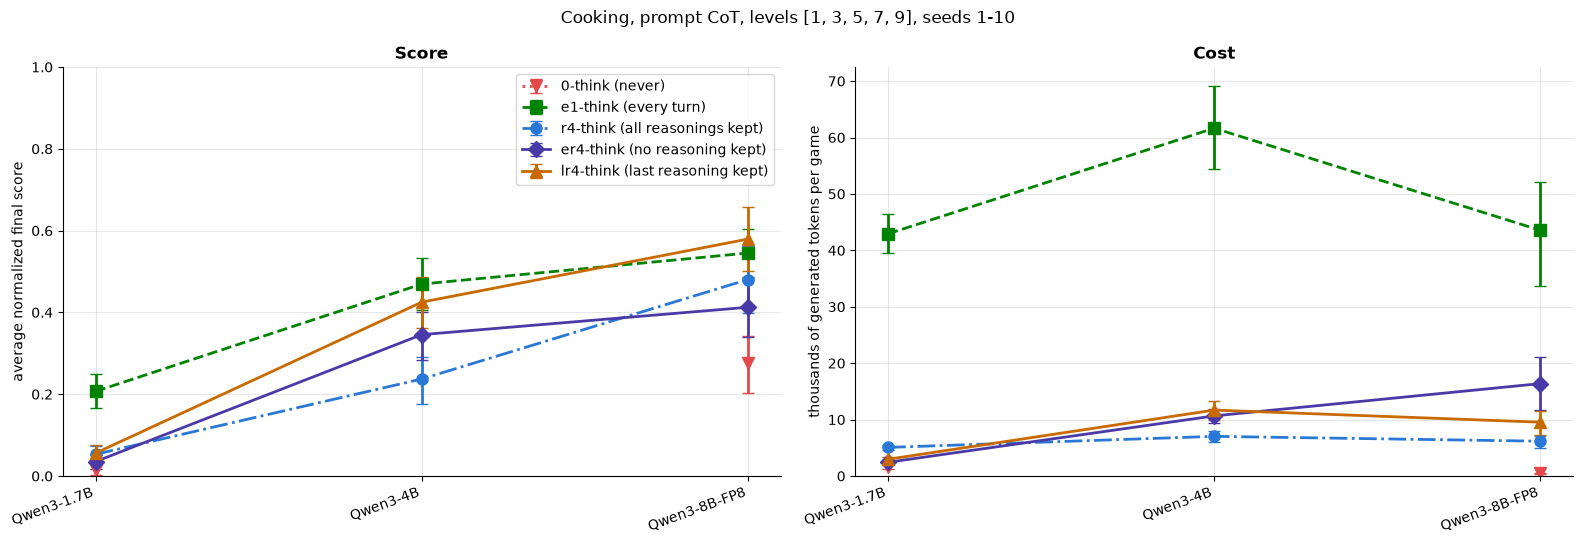

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
x = np.arange(len(models))
for column, (data, value, ylabel, title) in enumerate([
        (scores, lambda d: d.norm_score, "average normalized final score", "Score"),
        (tokens, lambda d: d.tokens_generated / 1000, "thousands of generated tokens per game", "Cost")]):
    ax = axes[column]
    for mode in modes:
        points = [mean_ci(value(data[(data.model == model) & (data["mode"] == mode)])) for model in models]
        y = np.array([p[0] for p in points])
        low = np.array([p[1] for p in points])
        high = np.array([p[2] for p in points])
        if np.isnan(y).all():
            continue
        ax.errorbar(x, y, yerr=[np.nan_to_num(y - low), np.nan_to_num(high - y)], capsize=4, linewidth=2,
                    markersize=8, label=labels[mode], **styles[mode])
    ax.set_xticks(x, [short[model] for model in models], rotation=20, ha="right")
    style_axis(ax, title, ylabel)
    ax.set_ylim(0, 1 if column == 0 else None)
    if column == 1:
        ax.set_ylim(bottom=0)
axes[0].legend()
fig.suptitle(f"{game.capitalize()}, prompt {prompt}, levels {levels}, seeds {seeds[0]}-{seeds[-1]}")
fig.tight_layout()
fig.savefig(f"graphs/models_{game}_{prompt}.pdf", bbox_inches="tight")
plt.show()

## Score against cost
One point per model and mode: higher is better, further left is cheaper. The label is the model.

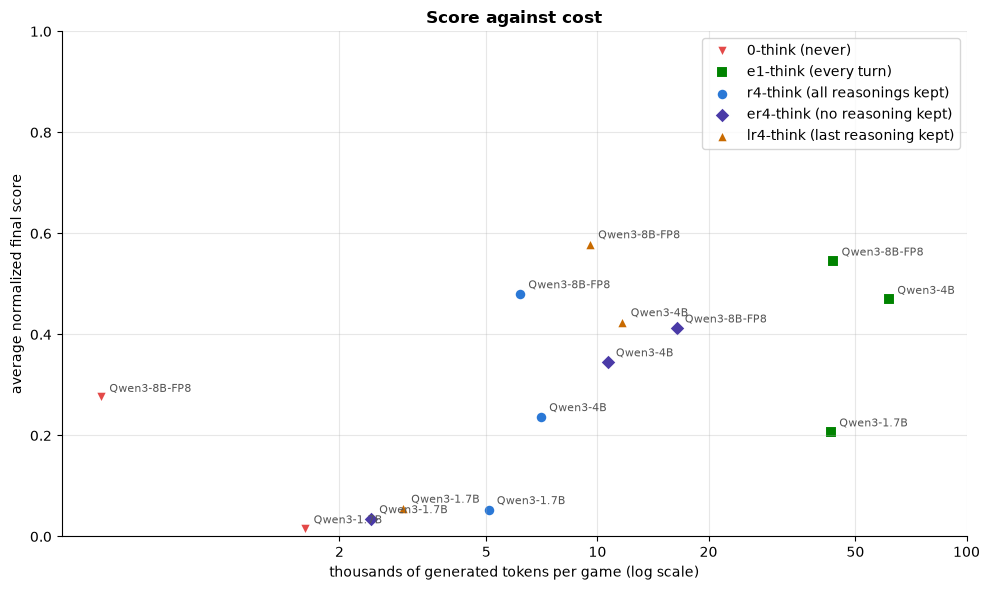

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
for mode in modes:
    labelled = False
    for model in models:
        s = scores[(scores.model == model) & (scores["mode"] == mode)]
        t = tokens[(tokens.model == model) & (tokens["mode"] == mode)]
        if len(s) == 0 or len(t) == 0:
            continue
        ax.scatter(t.tokens_generated.mean() / 1000, s.norm_score.mean(), s=70, color=styles[mode]["color"],
                   marker=styles[mode]["marker"], edgecolor="white", linewidth=1.5,
                   label=None if labelled else labels[mode])
        labelled = True
        ax.annotate(short[model], (t.tokens_generated.mean() / 1000, s.norm_score.mean()),
                    textcoords="offset points", xytext=(6, 4), fontsize=8, color="#555555")
ax.set_xscale("log")
ax.set_xticks([2, 5, 10, 20, 50, 100], ["2", "5", "10", "20", "50", "100"])
ax.minorticks_off()
ax.set_xlabel("thousands of generated tokens per game (log scale)")
style_axis(ax, "Score against cost", "average normalized final score")
ax.set_ylim(0, 1)
ax.legend()
fig.tight_layout()
fig.savefig(f"graphs/score_vs_cost_{game}_{prompt}.pdf", bbox_inches="tight")
plt.show()

## Score per level
One panel per model, as in the graphs of the old experiments.

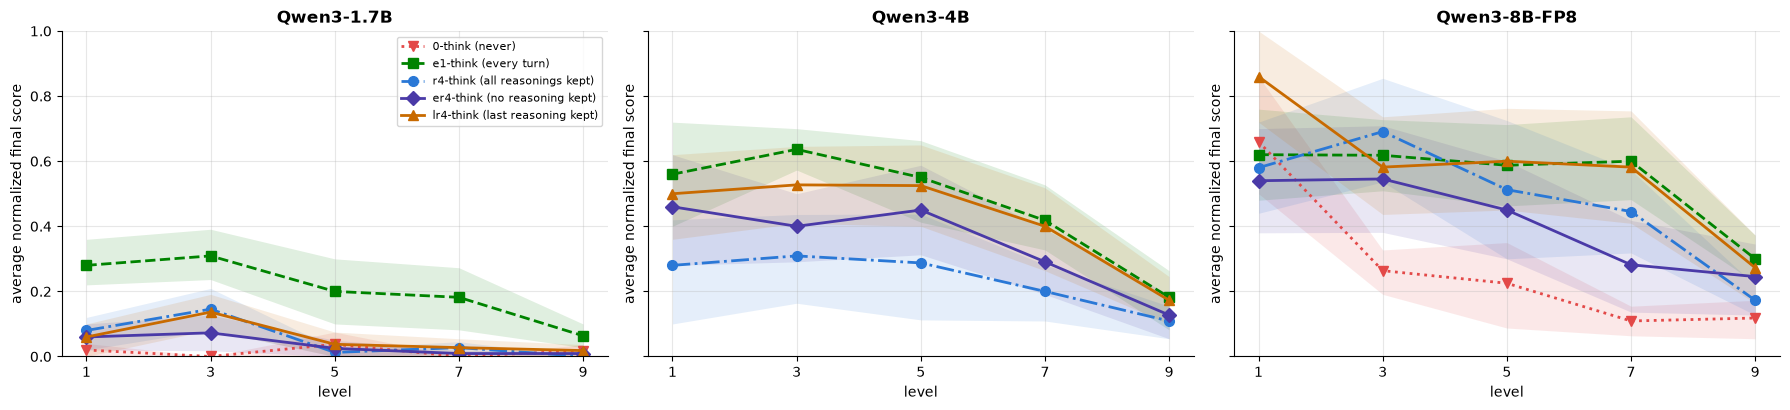

In [6]:
columns = min(3, len(models))
rows = int(np.ceil(len(models) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(6 * columns, 4.2 * rows), squeeze=False, sharey=True)
for ax, model in zip(axes.flat, models):
    for mode in modes:
        points = [(level, *mean_ci(scores[(scores.model == model) & (scores["mode"] == mode) & (scores.level == level)].norm_score))
                  for level in levels]
        points = [p for p in points if not np.isnan(p[1])]
        if not points:
            continue
        lx, y, low, high = (np.array(v) for v in zip(*points))
        ax.fill_between(lx, np.clip(np.where(np.isnan(low), y, low), 0, 1), np.clip(np.where(np.isnan(high), y, high), 0, 1),
                        color=styles[mode]["color"], alpha=0.12, linewidth=0)
        ax.plot(lx, y, label=labels[mode], linewidth=2, markersize=7, **styles[mode])
    style_axis(ax, short[model], "average normalized final score")
    ax.set_xlabel("level")
    ax.set_xticks(levels)
    ax.set_ylim(0, 1)
for ax in list(axes.flat)[len(models):]:
    ax.set_visible(False)
axes.flat[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"graphs/levels_{game}_{prompt}.pdf", bbox_inches="tight")
plt.show()

# Two-player games: which strategy plays better
The games of run_duel.py (grids/duel_*.yaml). The score of a game is 1 for a win, 0.5 for a draw and 0 for a loss, after Stockfish's adjudication when there is one (chess games stopped at max_steps); the advantage is Stockfish's evaluation of the final position, from the side of the player, in pawns (clipped to ±10, a mate counts as 10).
In self-play every game is counted twice, once for each player: the mode of the agent scores `score`, the mode of the opponent `1 - score`. The games of a mode against itself (e.g. e1 against self-e1) are left out of the totals: they always average 0.5.

In [7]:
duel_model = "Qwen/Qwen3-4B"
duel_game = "chess"
duel_prompt = "neutral"  # self-play: neutral (duel_selfplay.yaml), free (duel_free.yaml) or plain (duel_plain.yaml)
bot_prompt = "CoT"       # against the bots (duel_tier1)
duel_modes = ["0", "e1", "r4", "er4", "lr4"]

duels = table[table["source"] == "benchmark-duel"].copy() if "source" in table else table.iloc[:0].copy()
duels["level"] = duels.level.astype(str)
duels["final_score"] = duels.adjudicated_score.fillna(duels.score) if "adjudicated_score" in duels else duels.score

selfplay = duels[(duels.model == duel_model) & (duels.game == duel_game) & (duels.prompt == duel_prompt)
                 & duels.level.str.startswith("self-")]
sides = []
for _, row in selfplay.iterrows():
    opponent = row.level[len("self-"):]
    advantage = np.clip(row.final_eval, -1000, 1000) / 100 if pd.notna(row.get("final_eval")) else np.nan
    sides.append(dict(mode=row["mode"], against=opponent, score=row.final_score, advantage=advantage, seed=row.seed))
    sides.append(dict(mode=opponent, against=row["mode"], score=1 - row.final_score, advantage=-advantage, seed=row.seed))
sides = pd.DataFrame(sides, columns=["mode", "against", "score", "advantage", "seed"])
self_modes = [mode for mode in duel_modes if mode in set(sides["mode"])]
others = sides[sides["mode"] != sides.against] # without the games of a mode against itself
print(f"{len(selfplay)} self-play games of {short.get(duel_model, duel_model)}, {duel_game}, prompt {duel_prompt}")
pd.DataFrame([dict(mode=mode, games=len(s), wins=(s.score == 1).sum(), draws=(s.score == 0.5).sum(),
                   losses=(s.score == 0).sum(), score=s.score.mean(), advantage=s.advantage.mean())
              for mode in self_modes for s in [others[others["mode"] == mode]]]).set_index("mode").round(2)

8 self-play games of Qwen3-4B, chess, prompt neutral


,games,wins,draws,losses,score,advantage
mode,,,,,,
e1,4,0,4,0,0.5,4.00
r4,4,0,4,0,0.5,-0.58
er4,2,0,2,0,0.5,-1.96
lr4,2,0,2,0,0.5,-4.86


## Self-play: who beats whom
Left: the average score of the mode of the row against the mode of the column (blue: the row wins more, red: it loses more; n: games between the two). Middle: wins, draws and losses of each mode against all the other modes, with its average score. Right: the average advantage at the end of the games, which also separates the draws (e.g. a threefold repetition with a queen less) and the games stopped at max_steps.

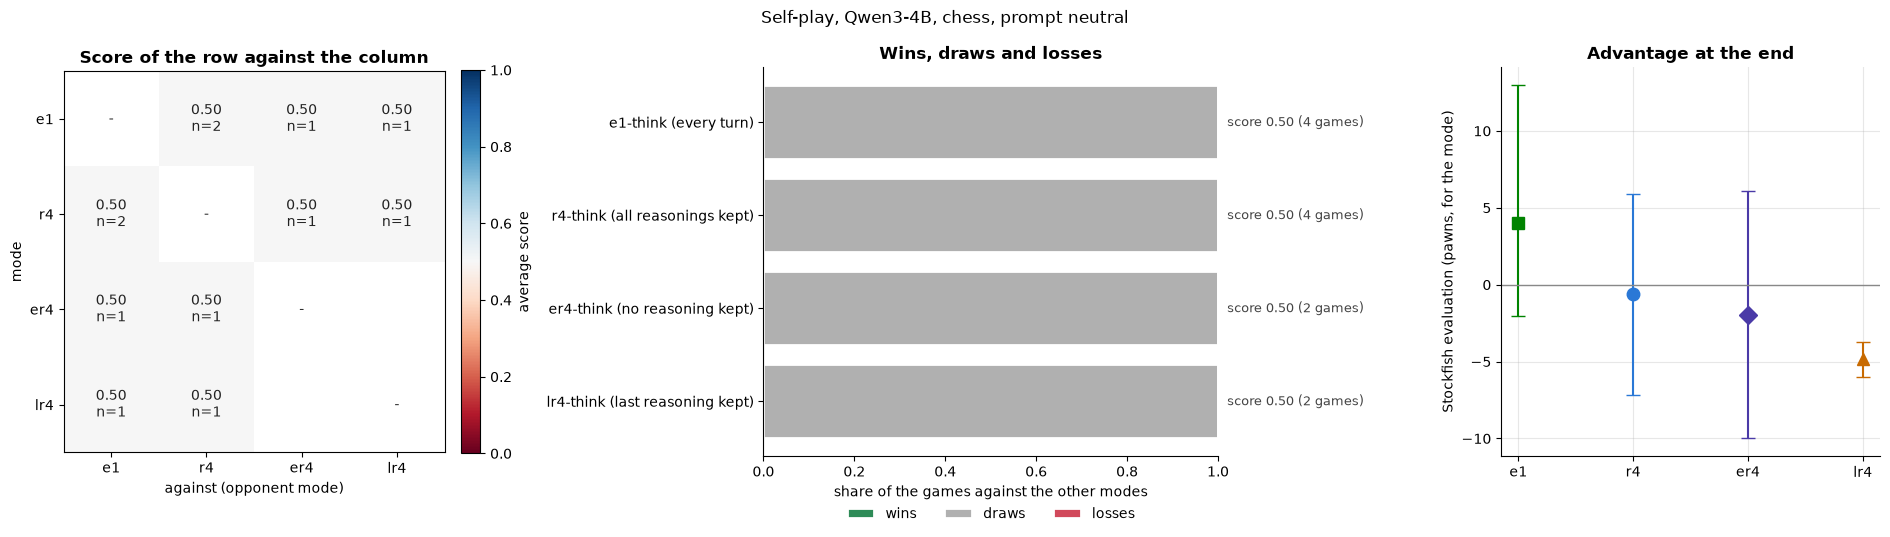

In [8]:
if len(sides) == 0:
    print("no self-play games: check duel_model, duel_game and duel_prompt")
else:
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw=dict(width_ratios=[1.1, 1.2, 1]))
    ax = axes[0]
    matrix = np.full((len(self_modes), len(self_modes)), np.nan)
    for i, mode in enumerate(self_modes):
        for j, against in enumerate(self_modes):
            s = sides[(sides["mode"] == mode) & (sides.against == against)]
            if len(s) and i != j:
                matrix[i, j] = s.score.mean()
            ax.text(j, i, "-" if i == j else f"{s.score.mean():.2f}\nn={len(s)}" if len(s) else "",
                    ha="center", va="center", fontsize=10, color="#222222")
    image = ax.imshow(matrix, cmap="RdBu", vmin=0, vmax=1)
    ax.set_xticks(range(len(self_modes)), self_modes)
    ax.set_yticks(range(len(self_modes)), self_modes)
    ax.set_xlabel("against (opponent mode)")
    ax.set_ylabel("mode")
    ax.set_title("Score of the row against the column", weight="bold")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="average score")

    ax = axes[1]
    y = np.arange(len(self_modes))
    left = np.zeros(len(self_modes))
    for value, name, color in ((1, "wins", "#2e8b57"), (0.5, "draws", "#b0b0b0"), (0, "losses", "#d1495b")):
        share = np.array([(others[others["mode"] == mode].score == value).mean() for mode in self_modes])
        ax.barh(y, share, left=left, color=color, edgecolor="white", linewidth=2, label=name)
        left += share
    for i, mode in enumerate(self_modes):
        s = others[others["mode"] == mode]
        ax.text(1.02, i, f"score {s.score.mean():.2f} ({len(s)} games)", va="center", fontsize=9, color="#444444")
    ax.set_yticks(y, [labels[mode] for mode in self_modes])
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of the games against the other modes")
    ax.set_title("Wins, draws and losses", weight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)

    ax = axes[2]
    for i, mode in enumerate(self_modes):
        mean, low, high = mean_ci(others[others["mode"] == mode].advantage.dropna())
        ax.errorbar(i, mean, yerr=[[np.nan_to_num(mean - low)], [np.nan_to_num(high - mean)]], capsize=5,
                    markersize=9, color=styles[mode]["color"], marker=styles[mode]["marker"])
    ax.axhline(0, color="#888888", linewidth=1)
    ax.set_xticks(range(len(self_modes)), self_modes)
    style_axis(ax, "Advantage at the end", "Stockfish evaluation (pawns, for the mode)")

    fig.suptitle(f"Self-play, {short.get(duel_model, duel_model)}, {duel_game}, prompt {duel_prompt}")
    fig.tight_layout()
    fig.savefig(f"graphs/selfplay_{duel_game}_{duel_prompt}_{duel_model.split('/')[-1]}.pdf", bbox_inches="tight")
    plt.show()

## Against the bots
The average score of every mode against each opponent (from the weakest to the strongest), one panel per model; the dotted line is an even result. Shaded areas: 90% bootstrap confidence intervals.

In [9]:
def opponent_order(level):
    """random, greedy, then Stockfish by skill (sf<N>) and by Elo (elo<N>)."""
    number = "".join(char for char in level if char.isdigit())
    return {"random": 0, "greedy": 1}.get(level, 2), level.startswith("elo"), int(number or 0)

bots = duels[(duels.prompt == bot_prompt) & ~duels.level.str.startswith("self-")]
for game_name in sorted(set(bots.game)):
    g = bots[bots.game == game_name]
    game_models = [model for model in models + sorted(set(g.model) - set(models)) if model in set(g.model)]
    opponents = sorted(set(g.level), key=opponent_order)
    columns = min(3, len(game_models))
    rows = int(np.ceil(len(game_models) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(6 * columns, 4.2 * rows), squeeze=False, sharey=True)
    x = np.arange(len(opponents))
    for ax, model in zip(axes.flat, game_models):
        for mode in duel_modes:
            points = [mean_ci(g[(g.model == model) & (g["mode"] == mode) & (g.level == level)].final_score)
                      for level in opponents]
            mean = np.array([p[0] for p in points])
            if np.isnan(mean).all():
                continue
            low = np.array([p[1] for p in points])
            high = np.array([p[2] for p in points])
            ax.fill_between(x, np.clip(np.where(np.isnan(low), mean, low), 0, 1),
                            np.clip(np.where(np.isnan(high), mean, high), 0, 1),
                            color=styles[mode]["color"], alpha=0.12, linewidth=0)
            ax.plot(x, mean, label=labels[mode], linewidth=2, markersize=7, **styles[mode])
        ax.axhline(0.5, color="#888888", linestyle=":", linewidth=1)
        style_axis(ax, model.split("/")[-1], "average score (win 1, draw 0.5, loss 0)")
        ax.set_xticks(x, opponents)
        ax.set_xlabel("opponent")
        ax.set_ylim(0, 1)
    for ax in list(axes.flat)[len(game_models):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=8)
    fig.suptitle(f"{game_name}, prompt {bot_prompt}, against the bots")
    fig.tight_layout()
    fig.savefig(f"graphs/bots_{game_name}_{bot_prompt}.pdf", bbox_inches="tight")
    plt.show()
if len(bots) == 0:
    print(f"no games against the bots with prompt {bot_prompt}")

no games against the bots with prompt CoT
